# GSE164378: PBMC

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2022-03-17
> - Modified: 2026-1-17

> - Regner, Matthew J. et al. A multi-omic single-cell landscape of human gynecologic malignancies. Molecular Cell, Volume 81, Issue 23, 4924 - 4941.e10
> - [GSE164378](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE164378)
> - Organism: Homo sapiens
> - PBMC
> - 2021-06-24

---

# Experimental Design

> - CITE-seq -> 10X scRNA-seq (3' or 5' RNA)
> - ADT: 228 TotalSeq-A antibodies
> - HTO
> - Illumina NovaSeq 6000
> - Cell Ranger v3.1.0
> - ADT, HTO counts were quantified using [Alevin](https://salmon.readthedocs.io/en/latest/alevin.html)
> - GRCh38


In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378"

In [3]:
scrna <- file.path(data_dir, "matrix", "RNA_3P", "RNA") |>
    Read10X() |>
    CreateSeuratObject(project = "PBMC_3P")

In [4]:
scrna[["ADT"]] <- file.path(data_dir, "matrix", "RNA_3P", "ADT") |>
    Read10X() |>
    CreateAssay5Object()

In [5]:
# scrna[["HTO"]] <- file.path(data_dir, "matrix", "RNA_3P", "HTO") |>
#     Read10X() |>
#     CreateAssay5Object()

In [6]:
scrna

An object of class Seurat 
33766 features across 161764 samples within 2 assays 
Active assay: RNA (33538 features, 0 variable features)
 1 layer present: counts
 1 other assay present: ADT

In [7]:
metadata <- file.path(data_dir, "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    mutate(orig.ident = lane) |>
    select(-lane, -Phase)

In [8]:
scrna <- AddMetaData(scrna, metadata)

In [9]:
head(scrna@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_ADT,nFeature_ADT,donor,time,celltype.l1,celltype.l2,celltype.l3,Batch
,<chr>,<int>,<int>,<int>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
L1_AAACCCAAGAAACTCA,L1,10823,2915,7535,217,P2,7,Mono,CD14 Mono,CD14 Mono,Batch1
L1_AAACCCAAGACATACA,L1,5864,1617,6013,209,P1,7,CD4 T,CD4 TCM,CD4 TCM_1,Batch1
L1_AAACCCACAACTGGTT,L1,5067,1381,6620,213,P4,2,CD8 T,CD8 Naive,CD8 Naive,Batch1
L1_AAACCCACACGTACTA,L1,4786,1890,3567,202,P3,7,NK,NK,NK_2,Batch1
L1_AAACCCACAGCATACT,L1,6505,1621,6402,215,P4,7,CD8 T,CD8 Naive,CD8 Naive,Batch1
L1_AAACCCACATCAGTCA,L1,4332,1633,5297,212,P3,2,CD8 T,CD8 TEM,CD8 TEM_1,Batch1


# 2. Quality Control

Cell quality control has been completed.

In [10]:
table(scrna$time, scrna$donor)

   
      P1   P2   P3   P4   P5   P6   P7   P8
  0 6443 5978 4698 5307 7020 6093 8909 8916
  2 5917 5714 5002 5793 6933 7583 8200 9203
  7 5775 5513 4960 5990 7858 7066 8762 8131

## 1). Calculate Metrics

In [11]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    obj <- PercentageFeatureSet(
        obj, pattern = mt_pattern, col.name = "percent.mt")
    
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    obj <- PercentageFeatureSet(
        obj, pattern = rp_pattern, col.name = "percent.rp")
    
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )
    obj <- PercentageFeatureSet(
        obj, pattern = hb_pattern, col.name = "percent.hb")
    
    return(obj)
}

In [12]:
scrna <- calculate_qc_metrics(scrna, species = "human")

## 2). Cell Cycle Effect

In [13]:
calculate_cell_cycle_score <- function(
    obj, species = c("human", "mouse")) {

    species <- match.arg(species)

    cc_s <- switch(
        species,
        "human" = cc.genes$s.genes,
        "mouse" = stringr::str_to_title(cc.genes$s.genes),
        tolower(cc.genes$s.genes))
    
    cc_g2m <- switch(
        species,
        "human" = cc.genes$g2m.genes,
        "mouse" = stringr::str_to_title(cc.genes$g2m.genes),
        tolower(cc.genes$g2m.genes))
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        CellCycleScoring(s.features = cc_s, g2m.features = cc_g2m, 
                         set.ident = FALSE)

    return(obj)
}

In [14]:
scrna <- calculate_cell_cycle_score(scrna, species = "human")

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# 3. Initial Assessment

In [15]:
source("R/run_seurat_pipeline.R")

In [16]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


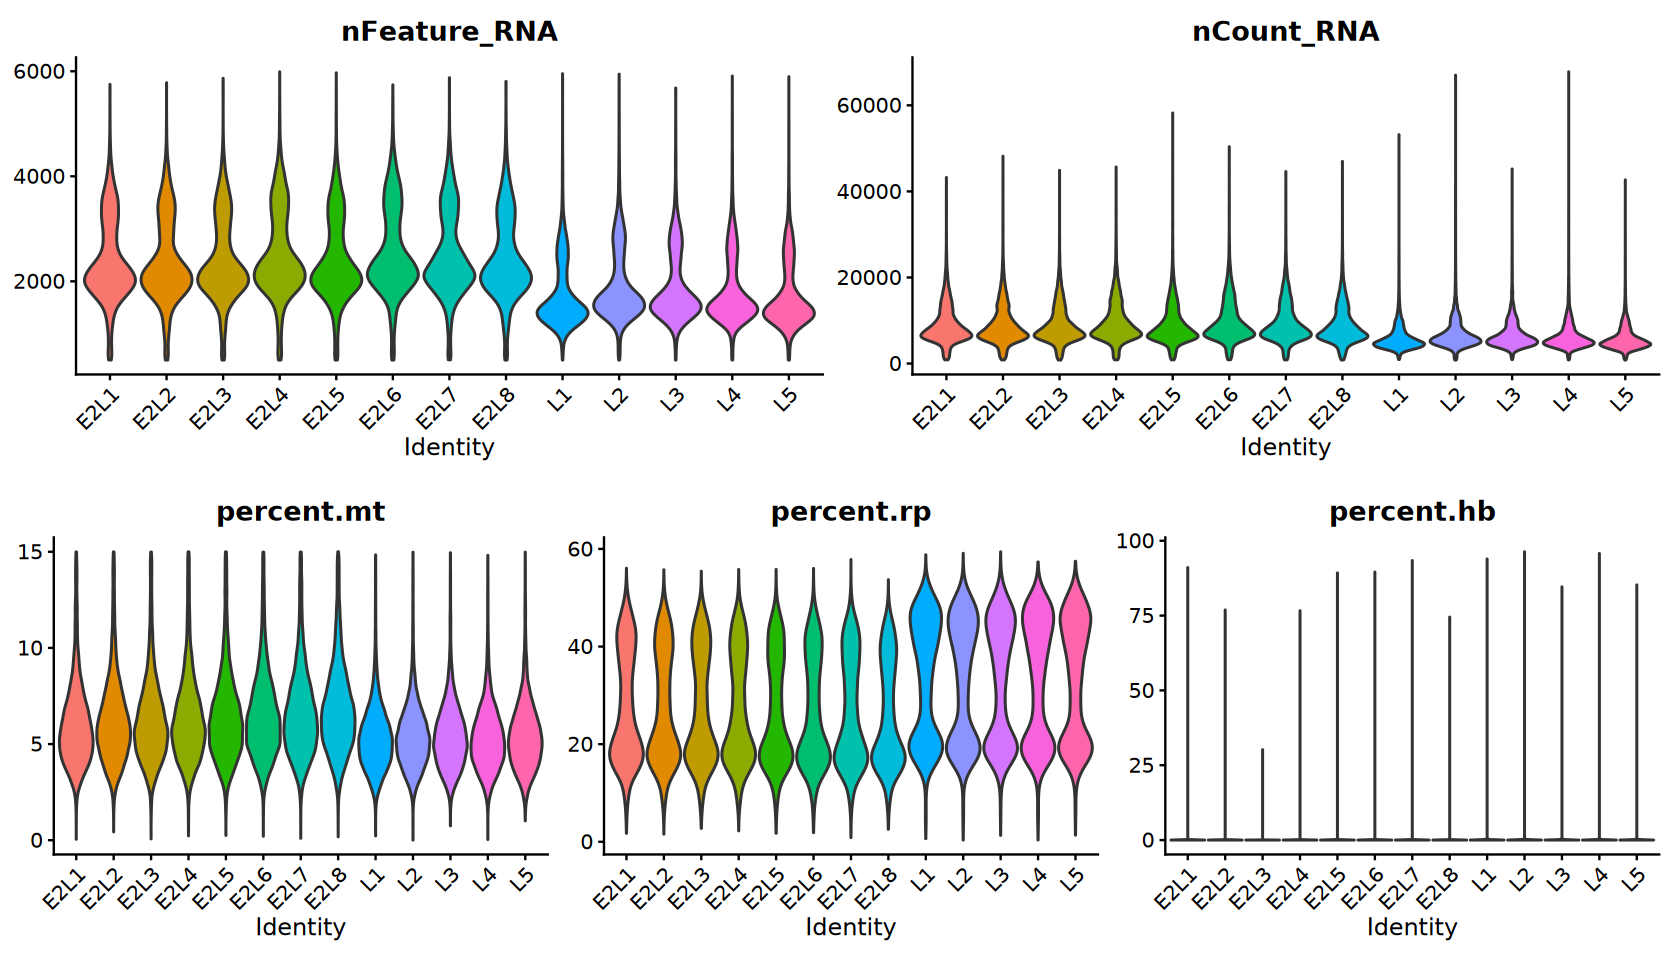

In [17]:
# Visualize QC metrics as a violin plot
p1 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("nFeature_RNA", "nCount_RNA"), 
    pt.size = 0, ncol = 2, raster = FALSE) & NoLegend()
p2 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("percent.mt", "percent.rp", "percent.hb"), 
    pt.size = 0, ncol = 3, raster = FALSE) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

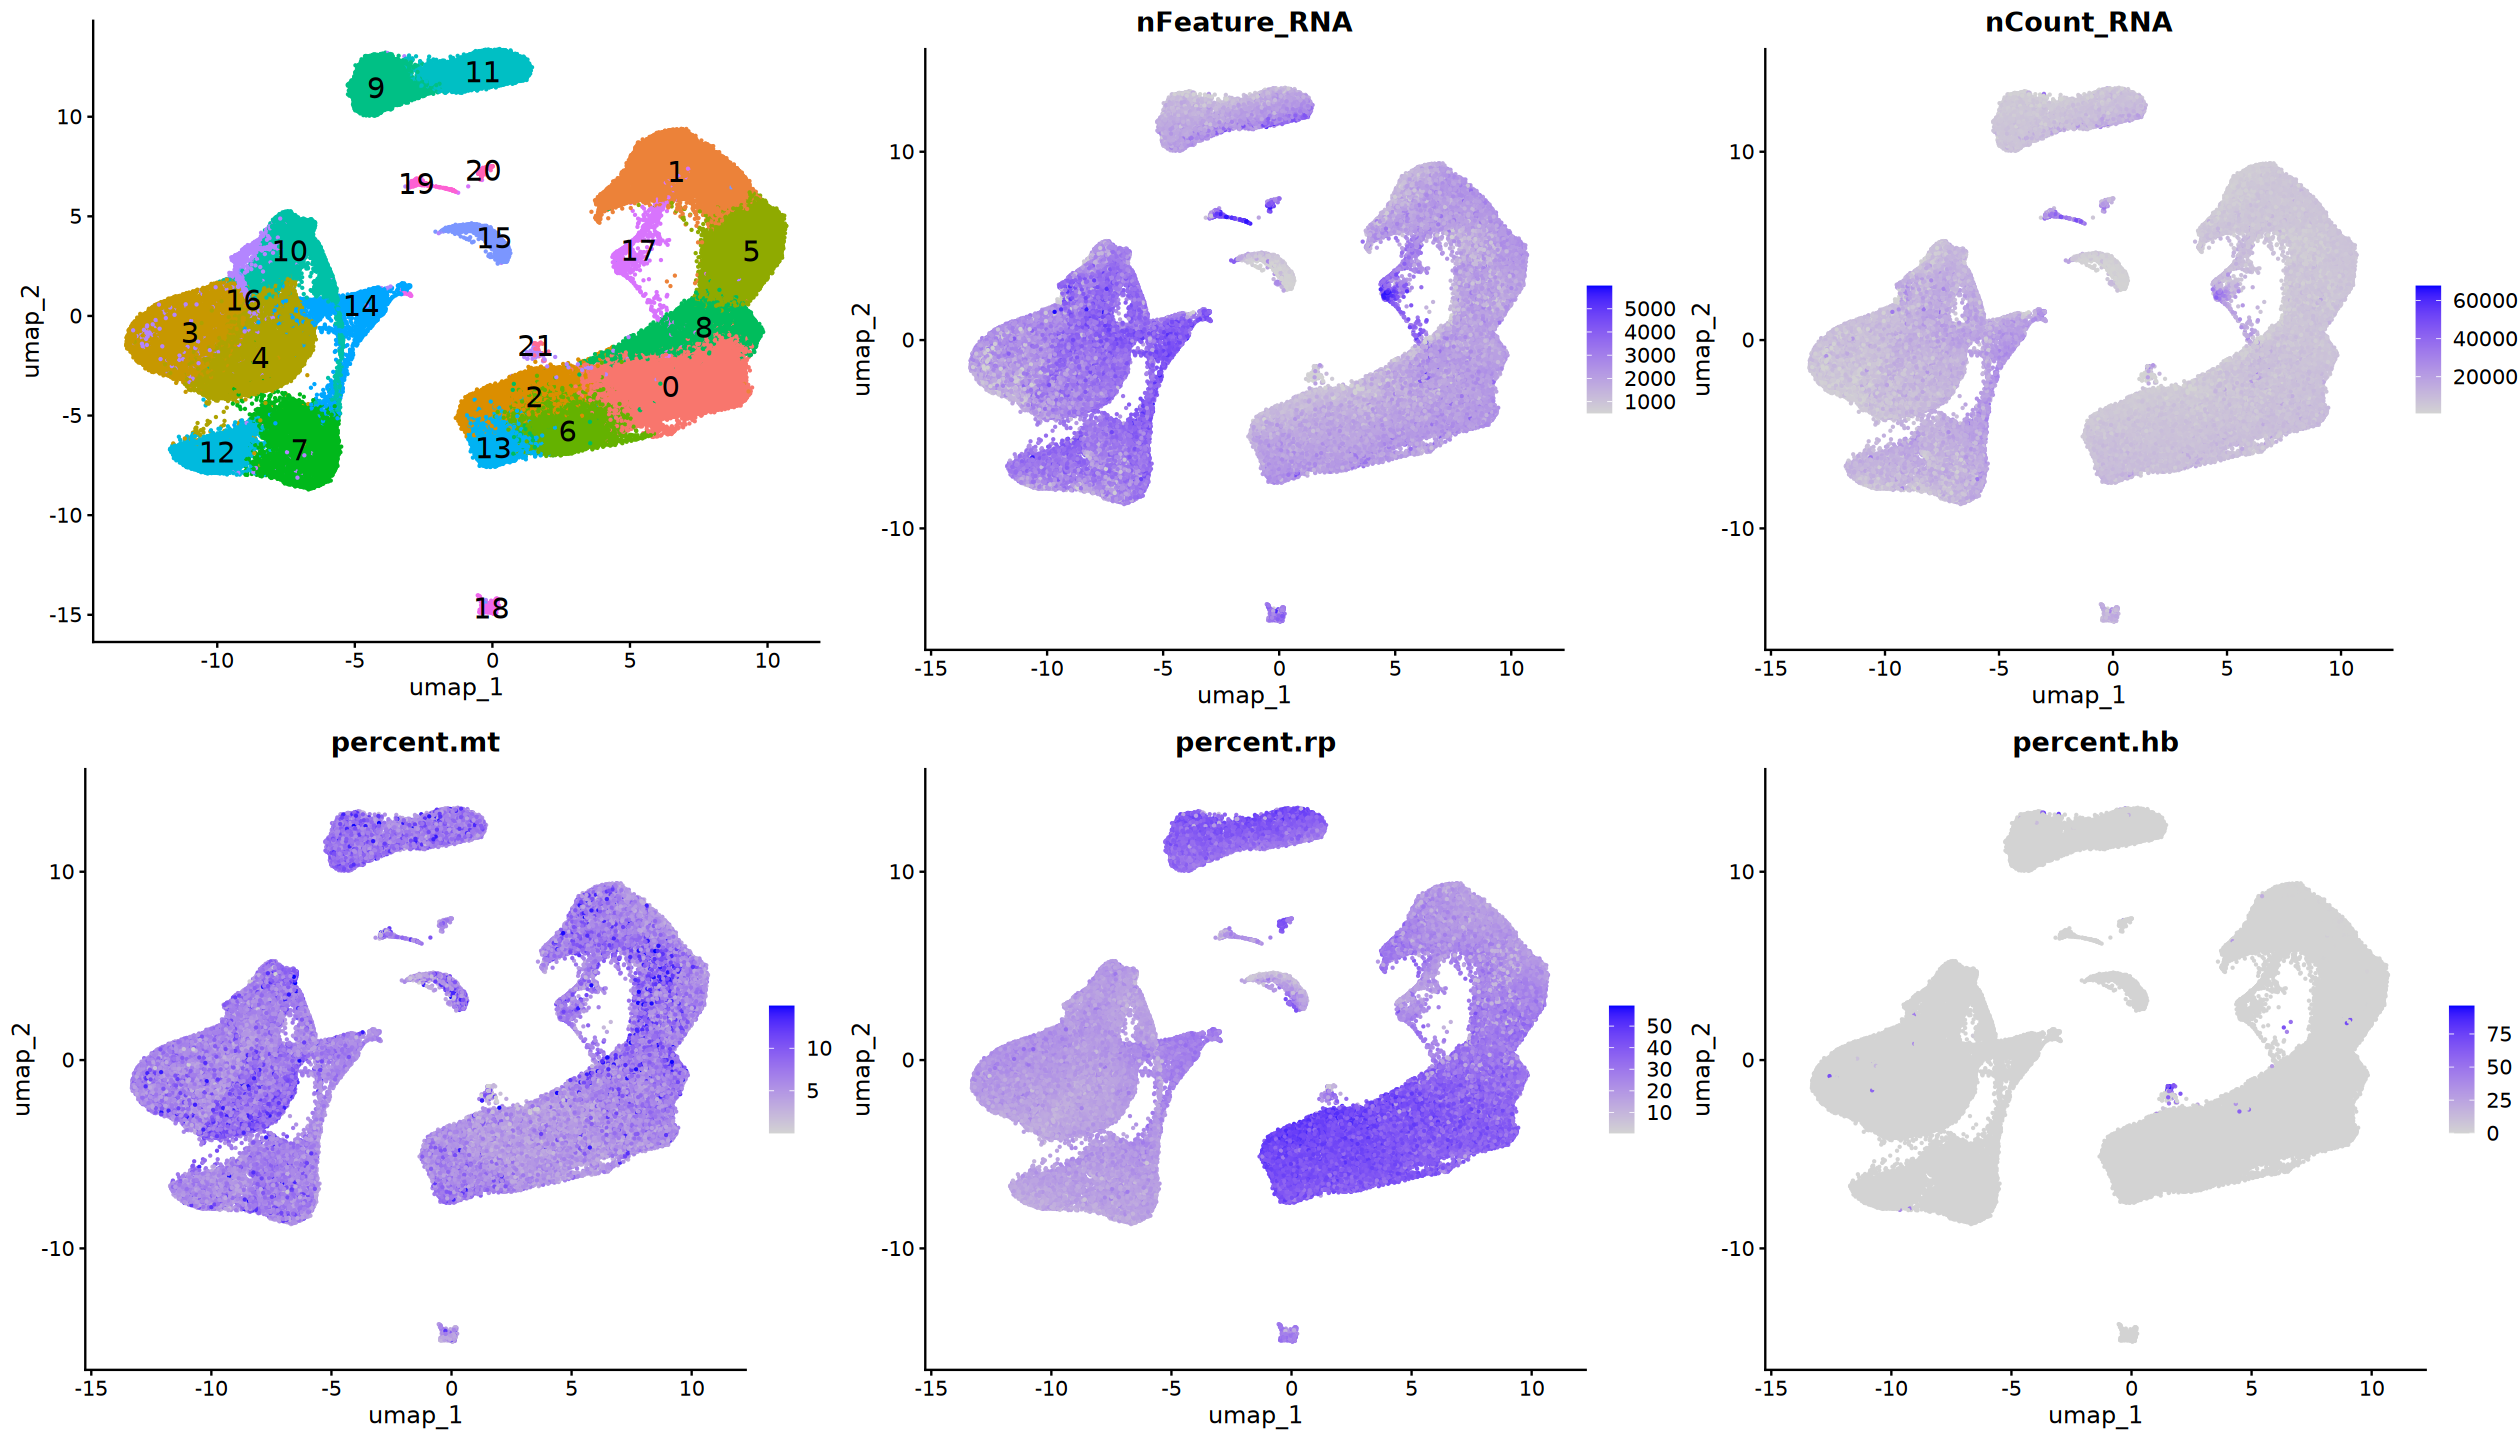

In [18]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6, raster = FALSE) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", 
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"), 
    combine = FALSE, raster = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

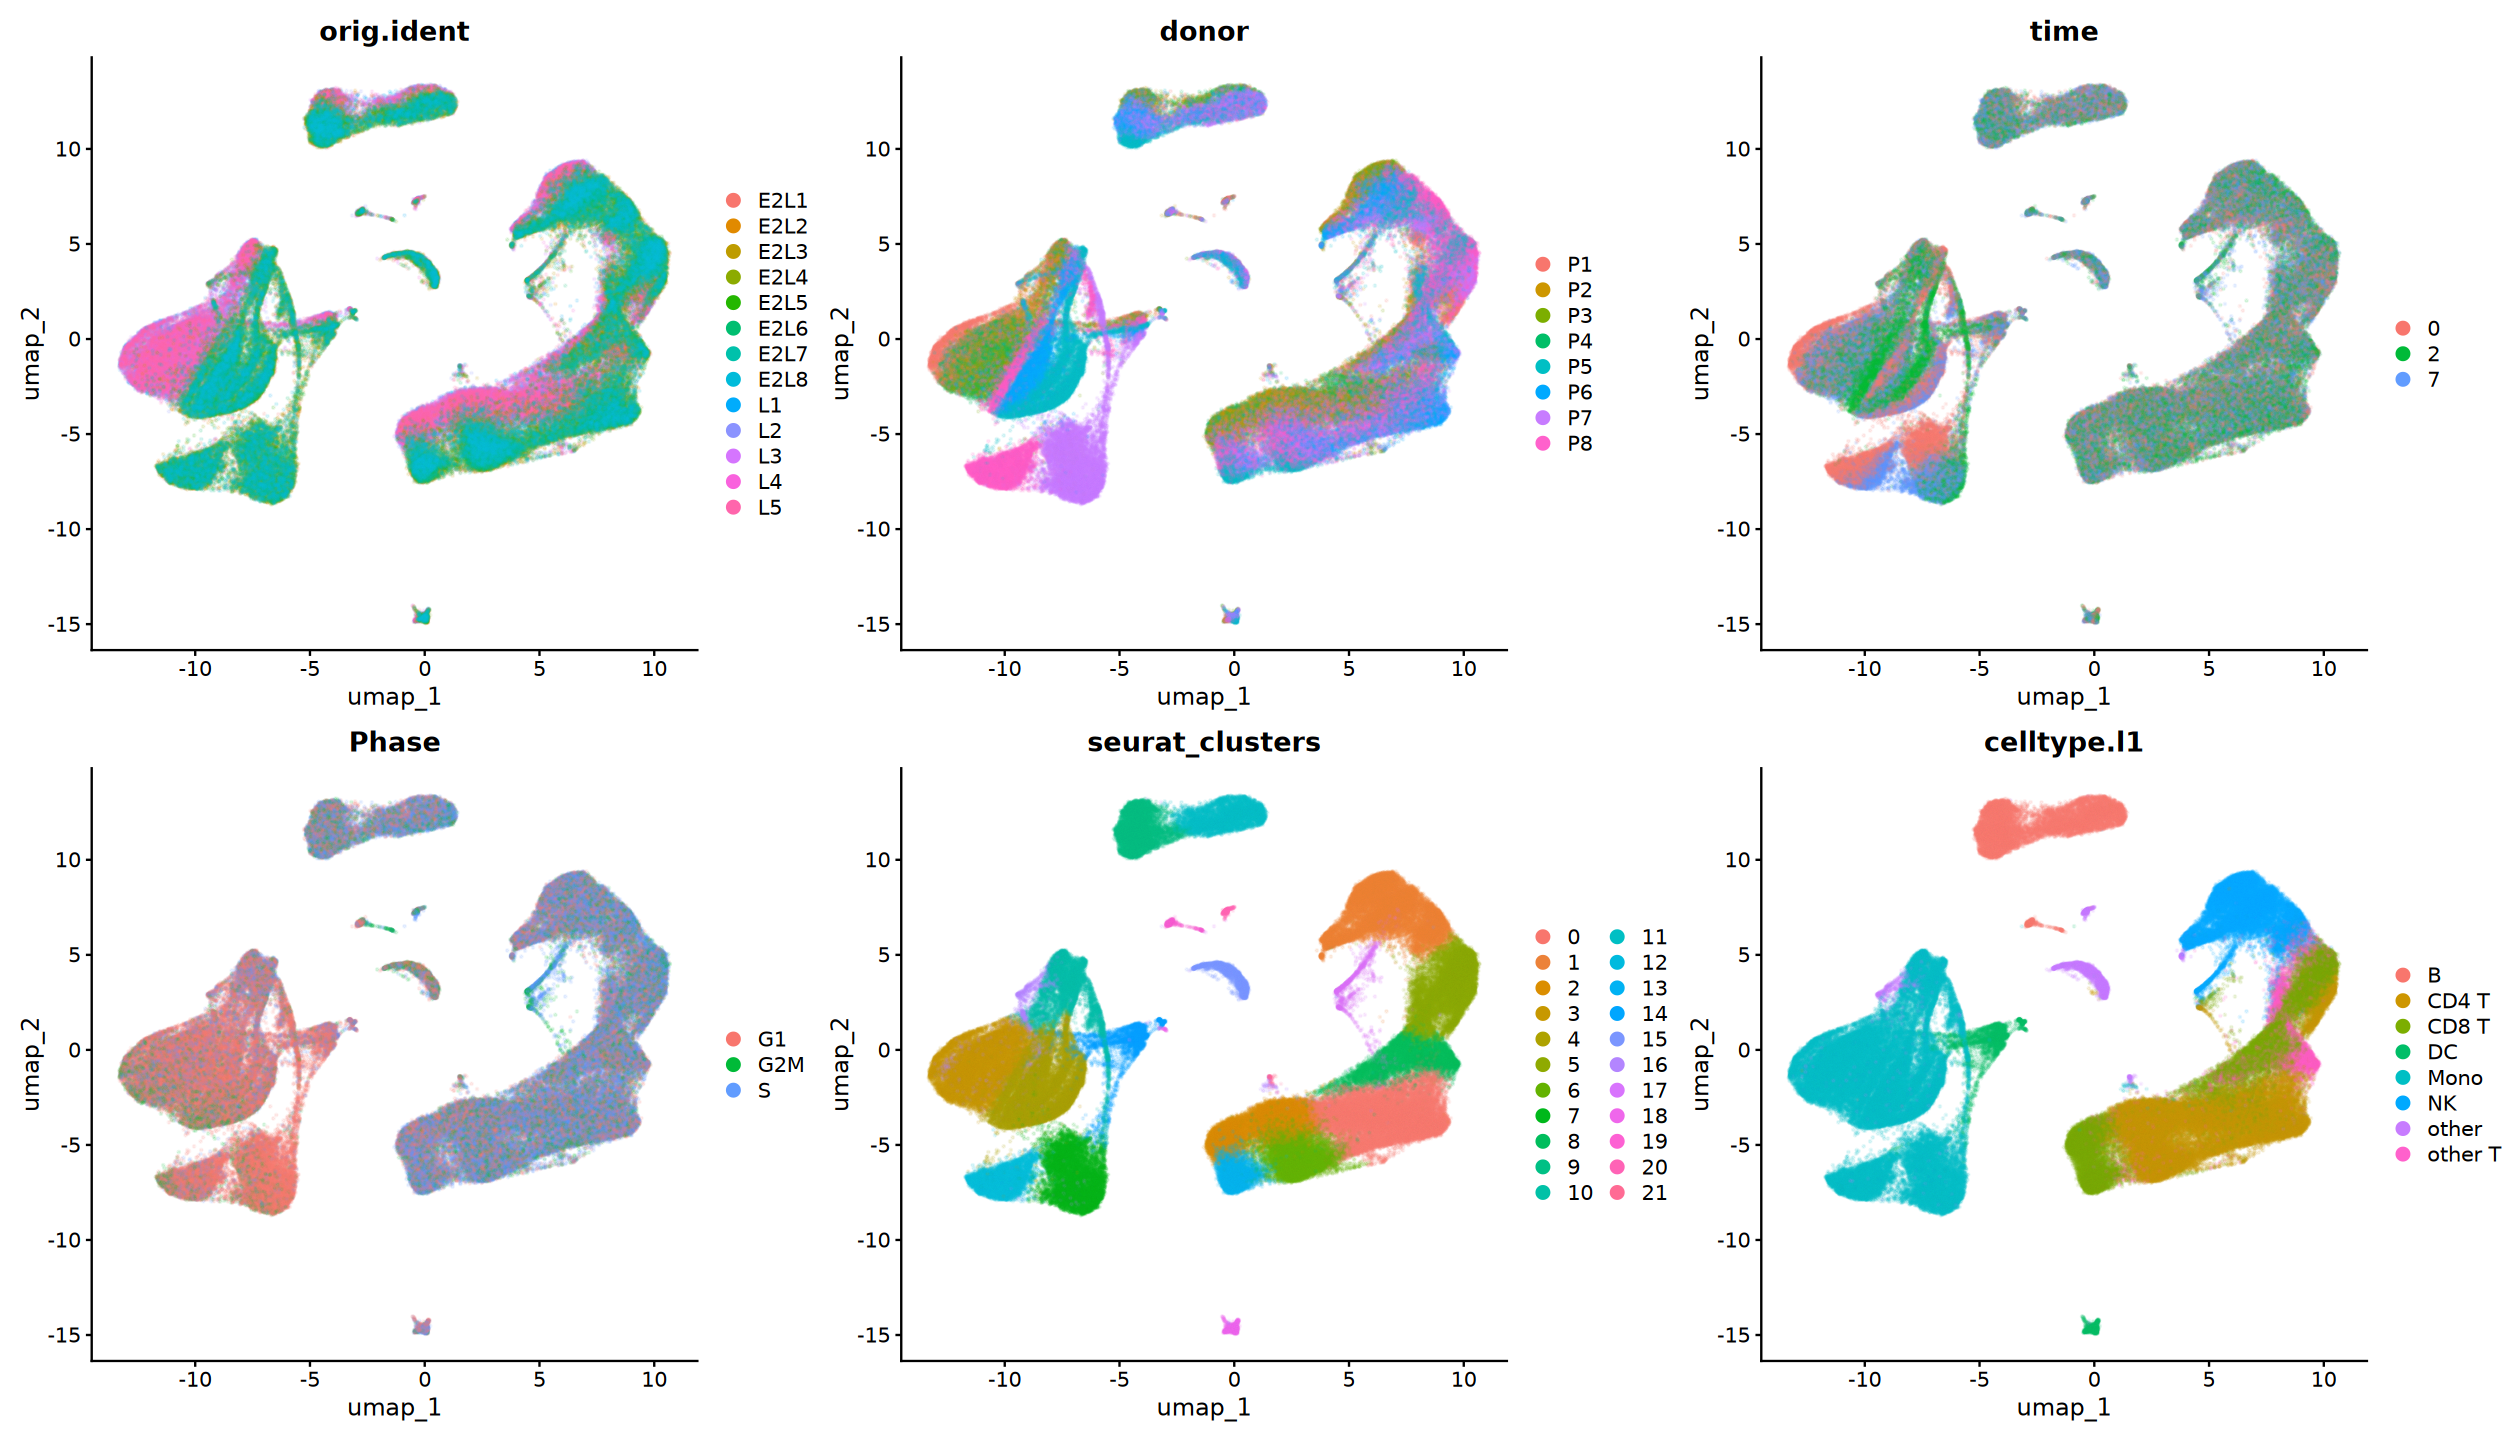

In [19]:
options(repr.plot.width = 21, repr.plot.height = 12)
DimPlot(sc.temp, reduction = "umap", 
        group.by = c("orig.ident", "donor", "time", "Phase", 
                     "seurat_clusters", "celltype.l1"), 
        pt.size = 0.1, alpha = 0.1,
        label = FALSE, raster = FALSE)

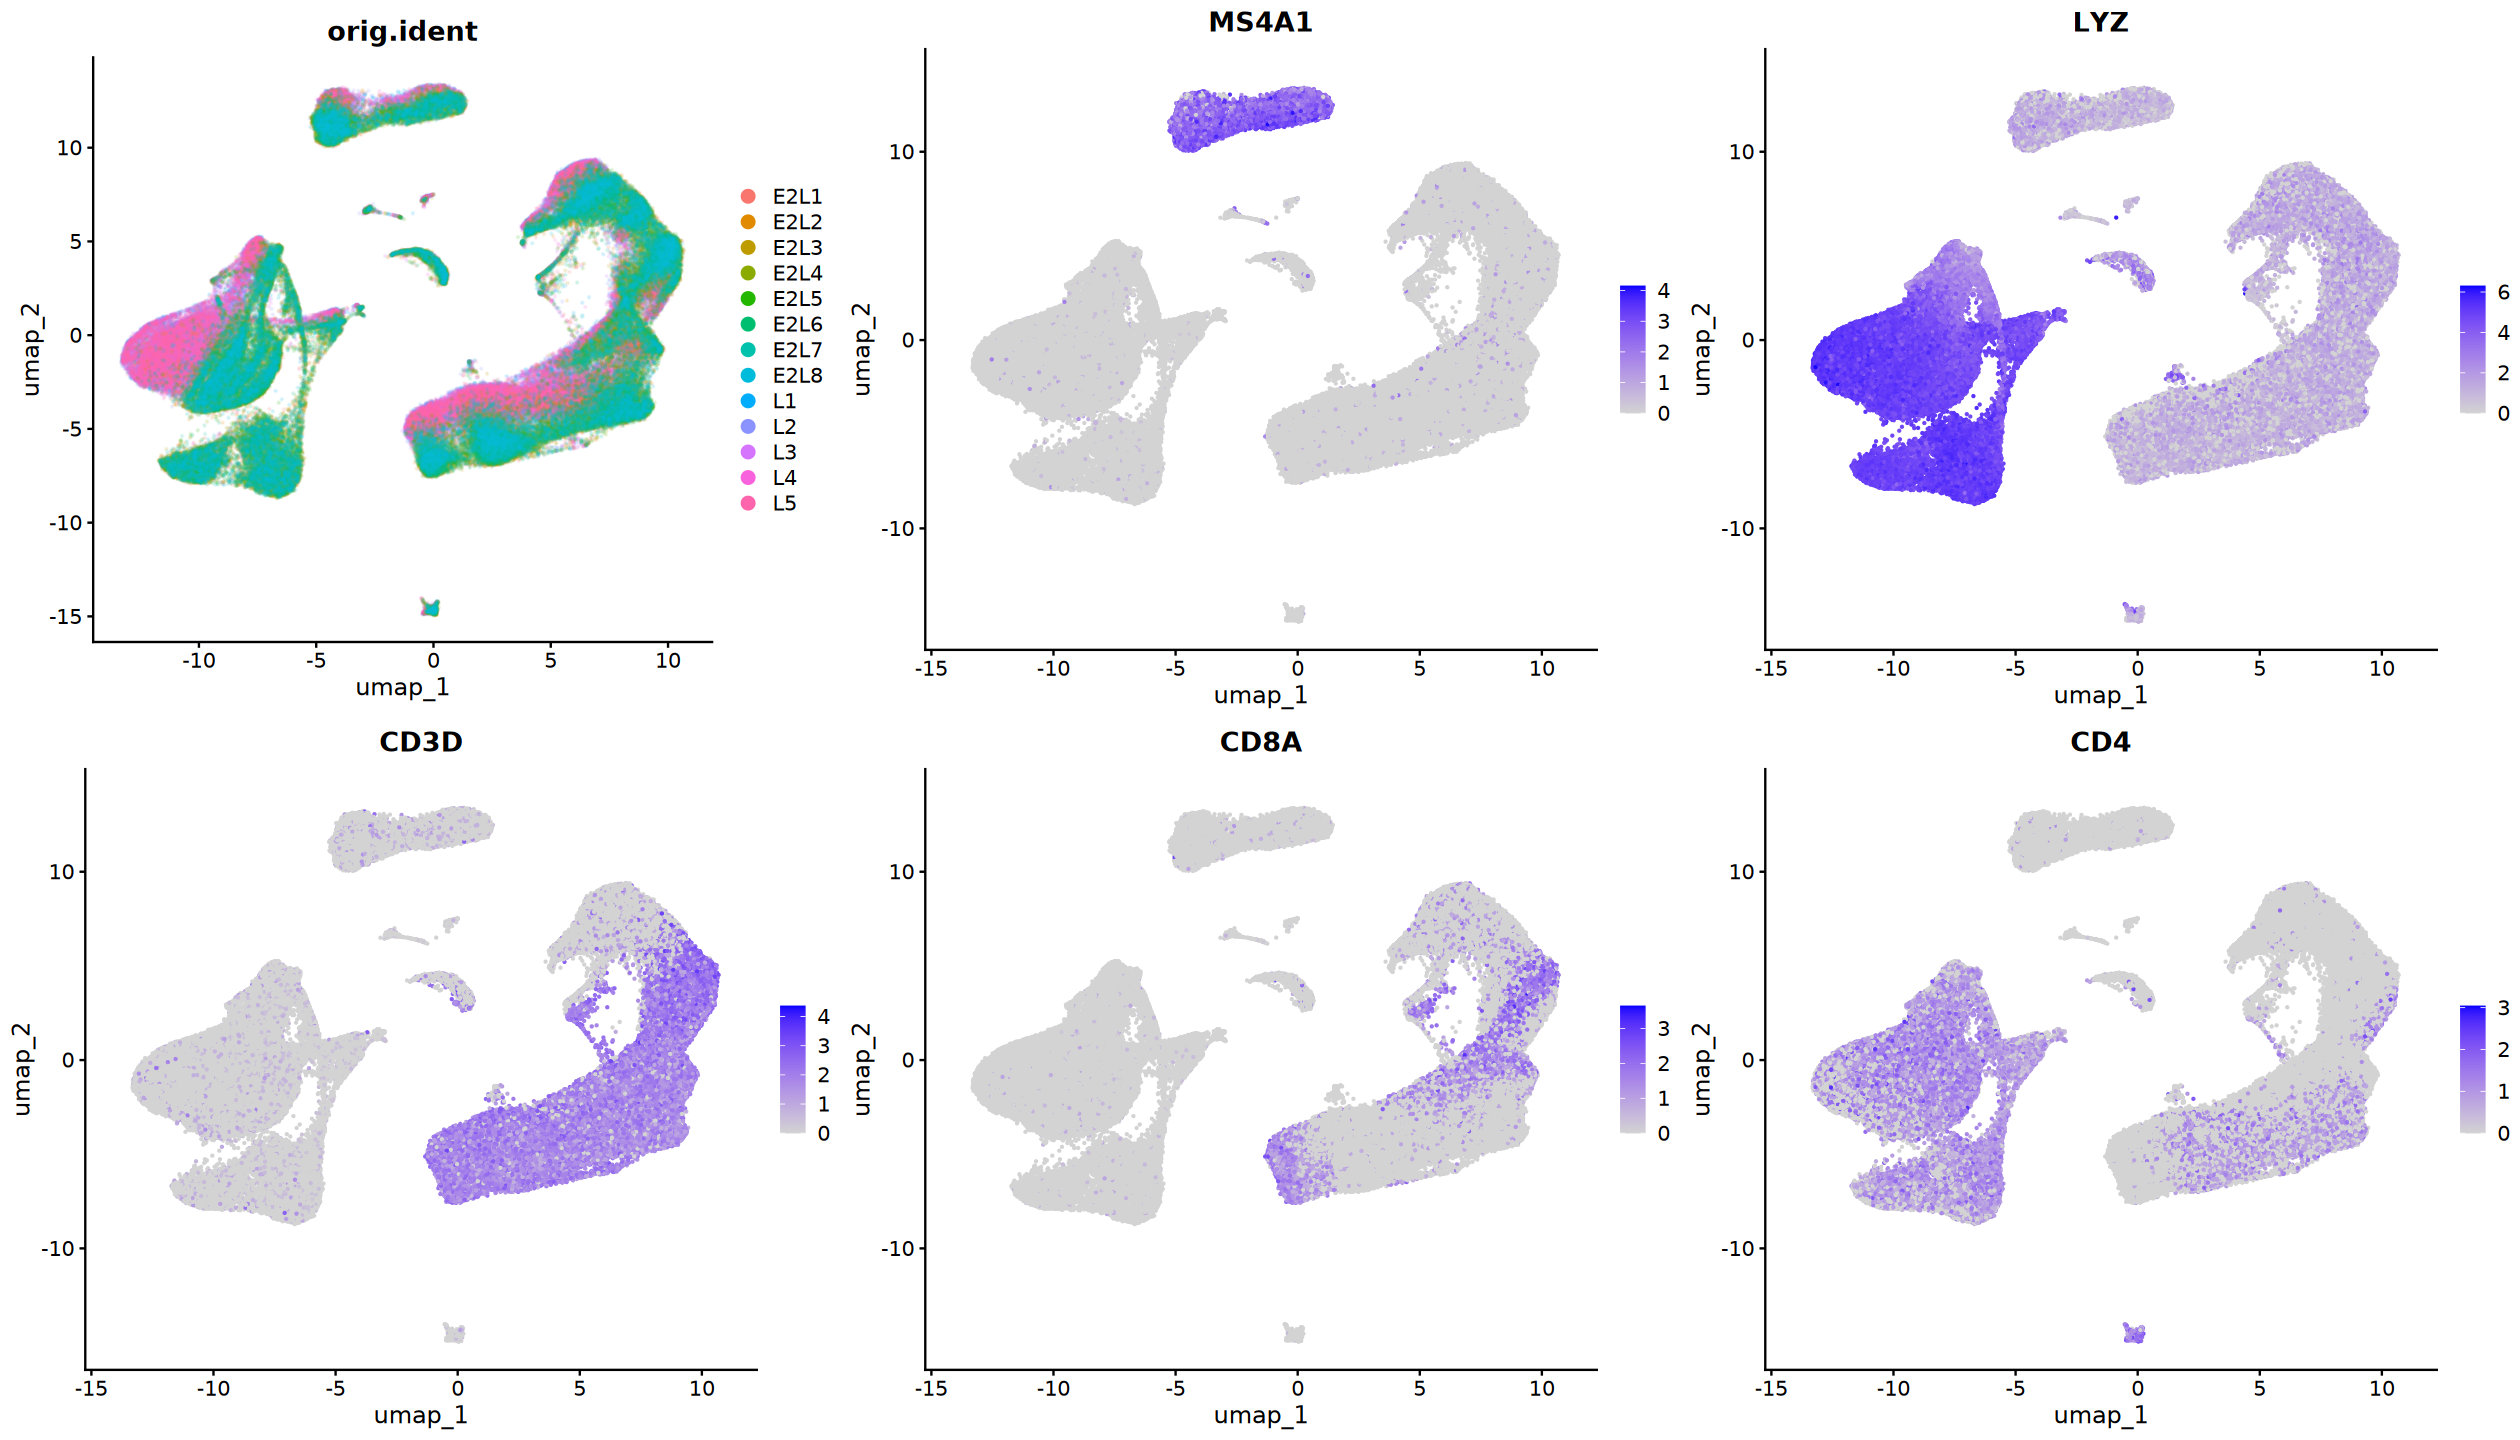

In [20]:
geneset <- c("MS4A1", "LYZ", "CD3D", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident", 
    pt.size = 0.1, alpha = 0.1, label = FALSE, 
    raster = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE, raster = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [21]:
rm(sc.temp)
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,4643081,248,7542458,402.9,7542458,402.9
Vcells,2016274017,15383,3385291526,25827.8,3385178007,25826.9


# 4. SCTransform

In [ ]:
scrna <- SCTransform(
    scrna, vars.to.regress = "percent.mt", verbose = FALSE)

# 5. Linear Dimensionality Reduction

In [ ]:
sc.comb <- RunPCA(sc.comb, npcs = 50, verbose = FALSE)

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "pca", alpha = 0.3)

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(sc.comb, ndims = 50)

In [ ]:
# Estimating PCA dimensionality
pca_var <- sc.comb@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

In [ ]:
nPCs <- 30

# 6. Integration

In [ ]:
sc.inte <- IntegrateLayers(
    sc.comb, method = CCAIntegration, orig.reduction = "pca", 
    new.reduction = "cca", verbose = FALSE)

In [ ]:
suppressPackageStartupMessages(library(harmony))

In [ ]:
sc.inte <- RunHarmony(sc.inte, "orig.ident", verbose = FALSE)

## Visualization

In [ ]:
sc.inte

In [ ]:
plot_inte_res <- function(obj, dims = 10, reduction) {
    
    obj <- RunUMAP(
        obj, dims = 1:dims, reduction = reduction, 
        verbose = FALSE)
    obj <- RunTSNE(
        obj, dims = 1:dims, reduction = reduction, 
        verbose = FALSE)

    p1 <- DimPlot(
        obj, reduction = reduction, group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    p2 <- DimPlot(
        obj, reduction = "umap", group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    p3 <- DimPlot(
        obj, reduction = "tsne", group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    
    plot_grid(p1, p2, p3, ncol = 1)
}

In [ ]:
methods <- c("pca", "cca", "harmony")

pg_list <- lapply(methods, function(redu) {
    plot_inte_res(sc.inte, nPCs, redu)
})

In [ ]:
titles <- c("non-integrate", "CCA", "Harmony")

title_list <- lapply(titles, function(text) {
    ggdraw() + draw_label(
        text, angle = 0, fontface = 'bold', size = 20)
})

In [ ]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(
    plot_grid(plotlist = title_list, ncol = 3), 
    plot_grid(plotlist = pg_list, ncol = 3), 
    ncol = 1, rel_heights = c(0.05, 1))

In [ ]:
inte <- "harmony"

In [ ]:
sc.inte <- JoinLayers(sc.inte)
sc.inte

# 7. Neighborhood Graph Construction

In [ ]:
sc.inte <- FindNeighbors(
    sc.inte, k.param = 20, reduction = inte, 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [ ]:
sc.inte <- RunUMAP(
    sc.inte, dims = seq_len(nPCs), reduction = inte, 
    verbose = FALSE)

In [ ]:
sc.inte <- RunTSNE(
    sc.inte, dims = seq_len(nPCs), reduction = inte,
    verbose = FALSE)

In [ ]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", pt.size = 0.1, alpha = 0.1)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", pt.size = 0.1, alpha = 0.1)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [ ]:
source("R/scan_clustering_resolution.R")

In [ ]:
cluster_list <- scan_clustering_resolution(
    sc.inte, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1), assess = FALSE)

In [ ]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [ ]:
sc.inte <- FindClusters(
    sc.inte, resolution = 0.1, verbose = FALSE)

In [ ]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6) & NoLegend()
p2 <- DimPlot(
    sc.inte, reduction = "tsne", label = TRUE,
    label.size = 6) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [ ]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6)
p3 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

# 10. Cluster Biomarkers

In [ ]:
sc.markers <- FindAllMarkers(
    sc.inte, logfc.threshold = log2(1.2), 
    min.pct = 0.25, only.pos = TRUE, 
    verbose = FALSE)

In [ ]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [ ]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

In [ ]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)
DotPlot(sc.inte, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 14),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))